In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
GPU available: []


In [3]:
# Dataset directories
DATASET_DIR = Path("../dataset/processed")

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "val"
TEST_DIR = DATASET_DIR / "test"

# Image configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

CLASS_NAMES = ["Abnormal", "Normal"]

print("Training directory:", TRAIN_DIR.resolve())
print("Validation directory:", VAL_DIR.resolve())
print("Testing directory:", TEST_DIR.resolve())

Training directory: D:\chest-xray-classification\dataset\processed\train
Validation directory: D:\chest-xray-classification\dataset\processed\val
Testing directory: D:\chest-xray-classification\dataset\processed\test


In [4]:
train_dataset = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

val_dataset = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=CLASS_NAMES,
    shuffle=False
)

test_dataset = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=CLASS_NAMES,
    shuffle=False
)

print("Classes:", train_dataset.class_names)

Found 700 files belonging to 2 classes.
Found 150 files belonging to 2 classes.
Found 150 files belonging to 2 classes.
Classes: ['Abnormal', 'Normal']


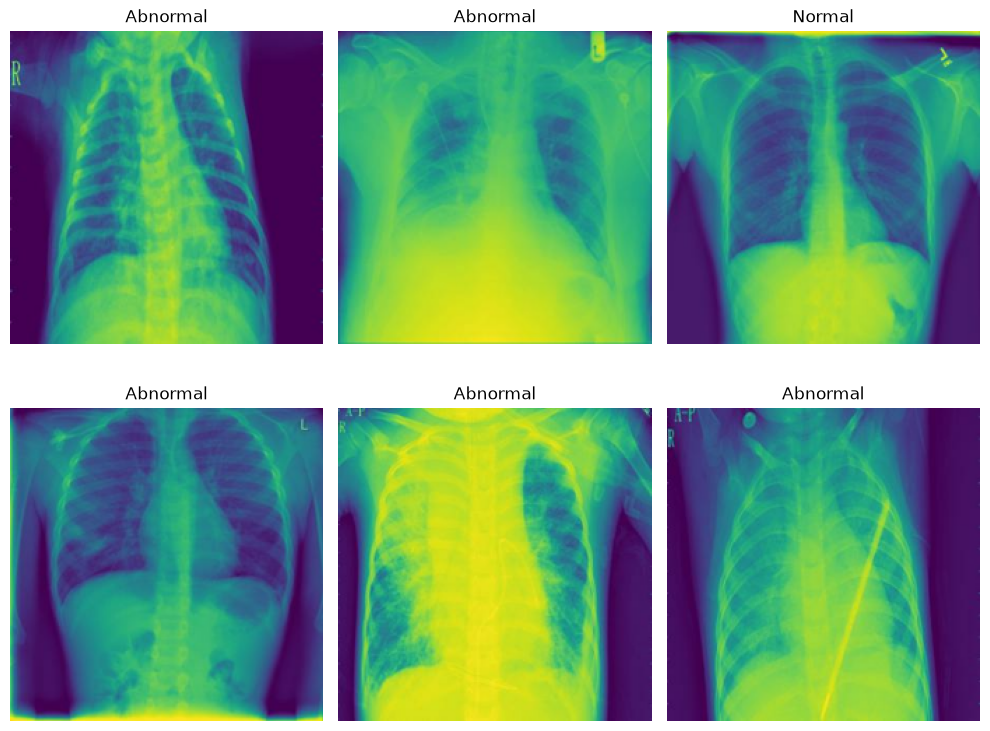

In [5]:
plt.figure(figsize=(10, 8))

for images, labels in train_dataset.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        label = int(labels[i][0].numpy())

        plt.title(CLASS_NAMES[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pre-trained layers initially
base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!


In [7]:
inputs = keras.Input(shape=(224, 224, 3))

# Preprocess images for MobileNetV2
x = keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract image features
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Binary classification output
outputs = layers.Dense(1, activation="sigmoid")(x)

# Create final model
model = keras.Model(inputs, outputs)

print("Classification model created!")

Classification model created!


In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
print("Total parameters:", model.count_params())

print(
    "Trainable parameters:",
    sum(tf.size(w).numpy() for w in model.trainable_weights)
)

print(
    "Non-trainable parameters:",
    sum(tf.size(w).numpy() for w in model.non_trainable_weights)
)

Total parameters: 2259265
Trainable parameters: 1281
Non-trainable parameters: 2257984


In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="../models/best_chest_xray_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

print("Training callbacks configured!")

Training callbacks configured!


In [11]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10


d:\chest-xray-classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


44/44 ━━━━━━━━━━━━━━━━━━━━ 33s 666ms/step - accuracy: 0.5100 - loss: 0.7255 - val_accuracy: 0.6400 - val_loss: 0.6428 - learning_rate: 1.0000e-04
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 22s 500ms/step - accuracy: 0.6157 - loss: 0.6569 - val_accuracy: 0.7133 - val_loss: 0.5844 - learning_rate: 1.0000e-04
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 468ms/step - accuracy: 0.6914 - loss: 0.6023 - val_accuracy: 0.7800 - val_loss: 0.5385 - learning_rate: 1.0000e-04
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 471ms/step - accuracy: 0.7443 - loss: 0.5618 - val_accuracy: 0.8133 - val_loss: 0.5032 - learning_rate: 1.0000e-04
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 477ms/step - accuracy: 0.7700 - loss: 0.5324 - val_accuracy: 0.8200 - val_loss: 0.4766 - learning_rate: 1.0000e-04
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 23s 514ms/step - accuracy: 0.7914 - loss: 0.5044 - val_accuracy: 0.8267 - val_loss: 0.4531 - learning_rate: 1.0000e-04
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 22s 501ms/step - accuracy: 0.79

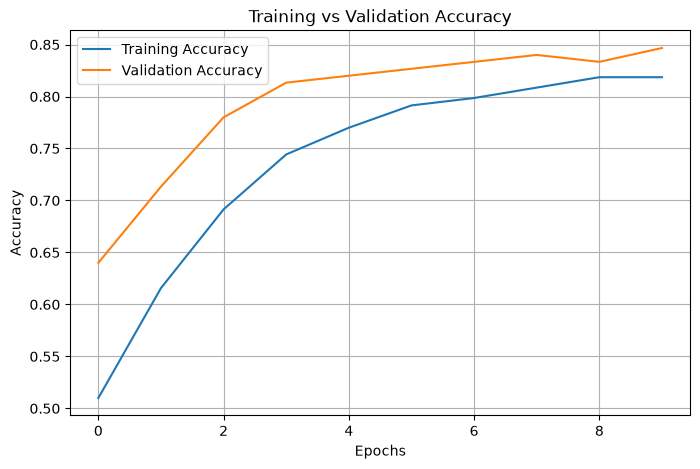

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

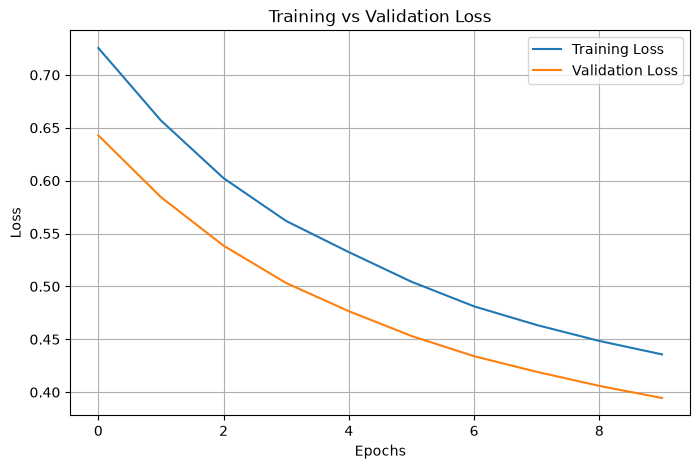

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import numpy as np
import matplotlib.pyplot as plt

In [15]:
# Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 426ms/step - accuracy: 0.7867 - loss: 0.4763
Test Loss: 0.4762783944606781
Test Accuracy: 0.7866666913032532


In [16]:
# Actual labels
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_dataset
])

# Predicted probabilities
y_prob = model.predict(test_dataset)

# Convert probabilities into class labels
y_pred = (y_prob.ravel() >= 0.5).astype(int)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 513ms/step
Actual labels: (150,)
Predicted labels: (150,)


In [17]:
print("Accuracy:", accuracy_score(y_true, y_pred))

print("Precision:", precision_score(y_true, y_pred))

print("Recall:", recall_score(y_true, y_pred))

print("F1 Score:", f1_score(y_true, y_pred))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Abnormal", "Normal"]
    )
)

Accuracy: 0.7866666666666666
Precision: 0.8028169014084507
Recall: 0.76
F1 Score: 0.7808219178082192

Classification Report:

              precision    recall  f1-score   support

    Abnormal       0.77      0.81      0.79        75
      Normal       0.80      0.76      0.78        75

    accuracy                           0.79       150
   macro avg       0.79      0.79      0.79       150
weighted avg       0.79      0.79      0.79       150



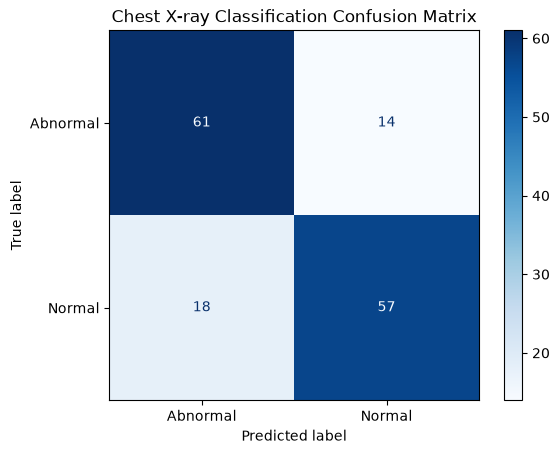

In [18]:
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Abnormal", "Normal"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Chest X-ray Classification Confusion Matrix")
plt.show()

In [19]:
model.save("../models/chest_xray_model.keras")

print("Model saved successfully!")

Model saved successfully!
